# Plotly Dash dashboard

Run python src/dashboard.py from the spacex-capstone directory. The dropdown changes site, and the range slider filters scatter points. The all-sites pie shows shares of successes, not per-site success rates.

Executed reconstruction created for this report. These are not recovered copies of previously unshared learner notebooks.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, json
from IPython.display import display, Image, HTML
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)


In [2]:
import sys
sys.path.insert(0,str(ROOT/'src'))
import dashboard
df=pd.read_csv(DATA/'spacex_launch_dash.csv');display(df.groupby('Launch Site')['class'].agg(['sum','count','mean']))

{'Coastline (sample point)': 0.9364802130779101, 'Road (sample point)': 0.43583571253050507, 'Rail corridor (sample point)': 1.4001057600690532}


,sum,count,mean
Launch Site,,,
CCAFS LC-40,7,26,0.269231
CCAFS SLC-40,3,7,0.428571
KSC LC-39A,10,13,0.769231
VAFB SLC-4E,4,10,0.400000


ALL [0, 10000] scatter points: 56
KSC LC-39A [0, 10000] scatter points: 13
ALL [5000, 10000] scatter points: 14


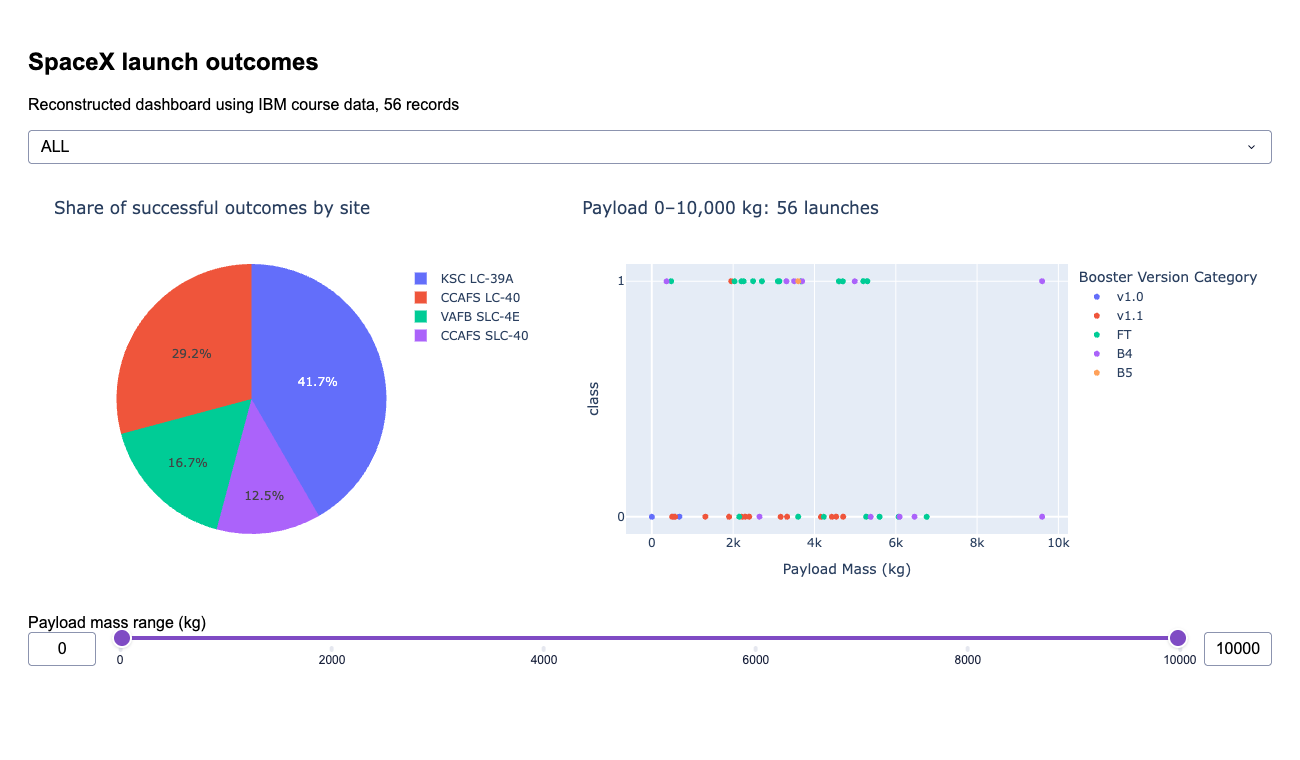

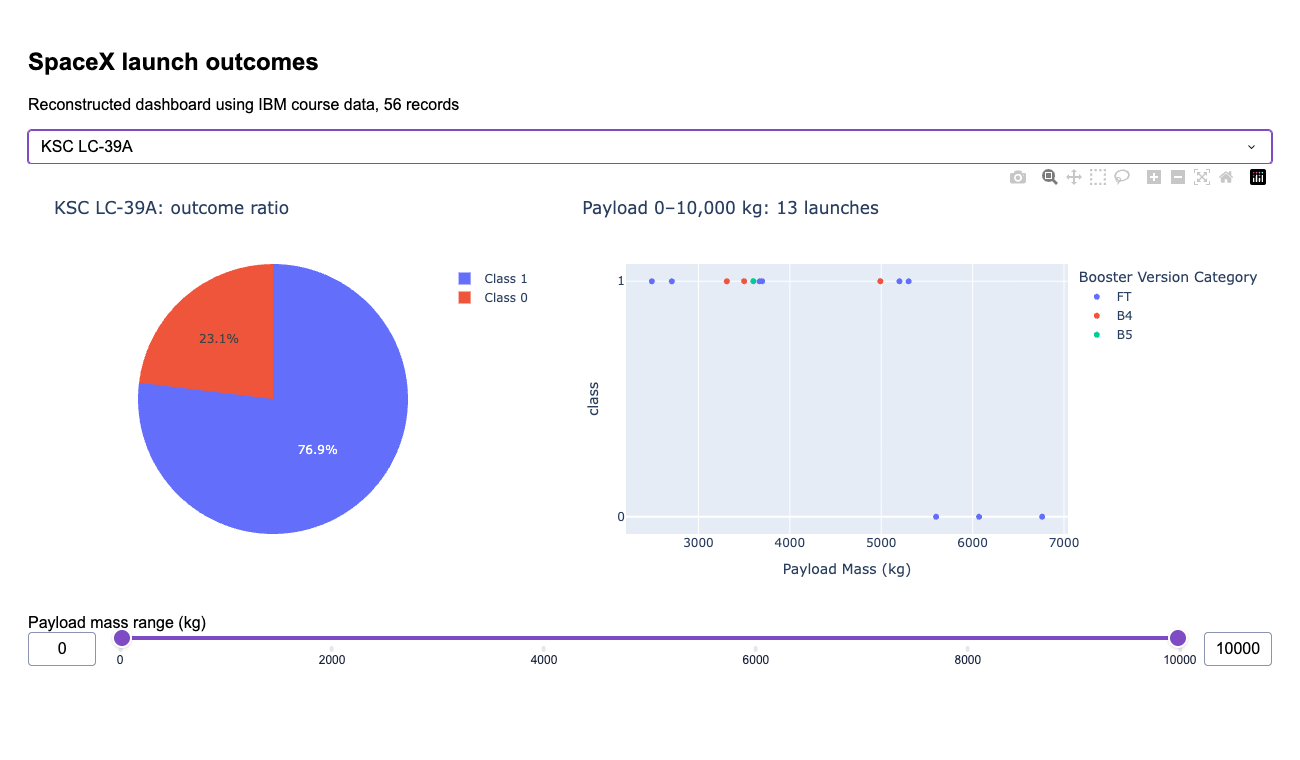

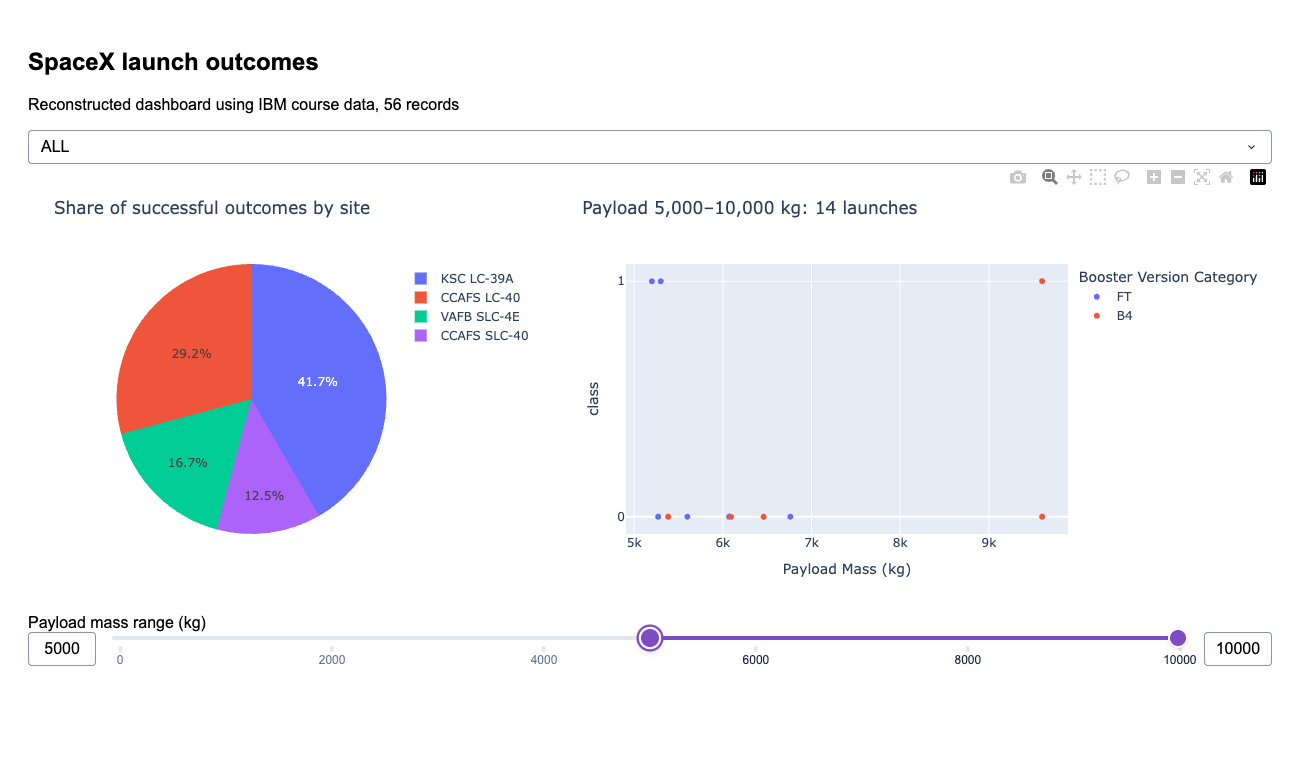

Dash layout: Div


In [3]:
for site,bounds in [('ALL',[0,10000]),('KSC LC-39A',[0,10000]),('ALL',[5000,10000])]:
    pie,scatter=dashboard.update(site,bounds)
    print(site,bounds,'scatter points:',sum(len(t.x) for t in scatter.data))
    assert len(scatter.data)>0
for name in ['dash1','dash2','dash3']:display(Image(filename=str(RESULTS/f'{name}.png')))
print('Dash layout:',type(dashboard.app.layout).__name__)